/opt/anaconda3/envs/das2env/lib/python3.9/site-packages/pdr/bit_handling.py:174: UserWarning: Data type LSB_UNSIGNED_INTEGER incompatible for bit column. Changing to MSB_BIT_STRING.
  warnings.warn(


Running Monte-Carlo: N_MC=20000000, NULL_MODEL='white', workers=10


/var/folders/fz/cnqc4h596ll_2kqzb_kkg3x40000gn/T/ipykernel_49320/166753797.py:119: RuntimeWarning: Mean of empty slice
  Z_mean = np.nanmean(cube, axis=2)      # (T, 64)


Monte-Carlo peak significance (global; max power in band):
  Peak at  3.53 min: power= 1.61e+25, p_MC= 1.00000
  Peak at  5.45 min: power= 1.71e+25, p_MC= 1.00000
  Peak at  8.57 min: power= 1.19e+25, p_MC= 1.00000
  Peak at 12.00 min: power= 4.42e+25, p_MC= 0.86847
Peaks with p_MC < 0.01 are 'significant' at that global level.


/var/folders/fz/cnqc4h596ll_2kqzb_kkg3x40000gn/T/ipykernel_49320/166753797.py:477: UserWarning: This figure includes Axes that are not compatible with tight_layout, so results might be incorrect.
  fig.tight_layout()


Saved → Segment Analysis Figures/JAD_L50_LRS_ELC_ANY_DEF_2019092_V01_segment_analysis.png


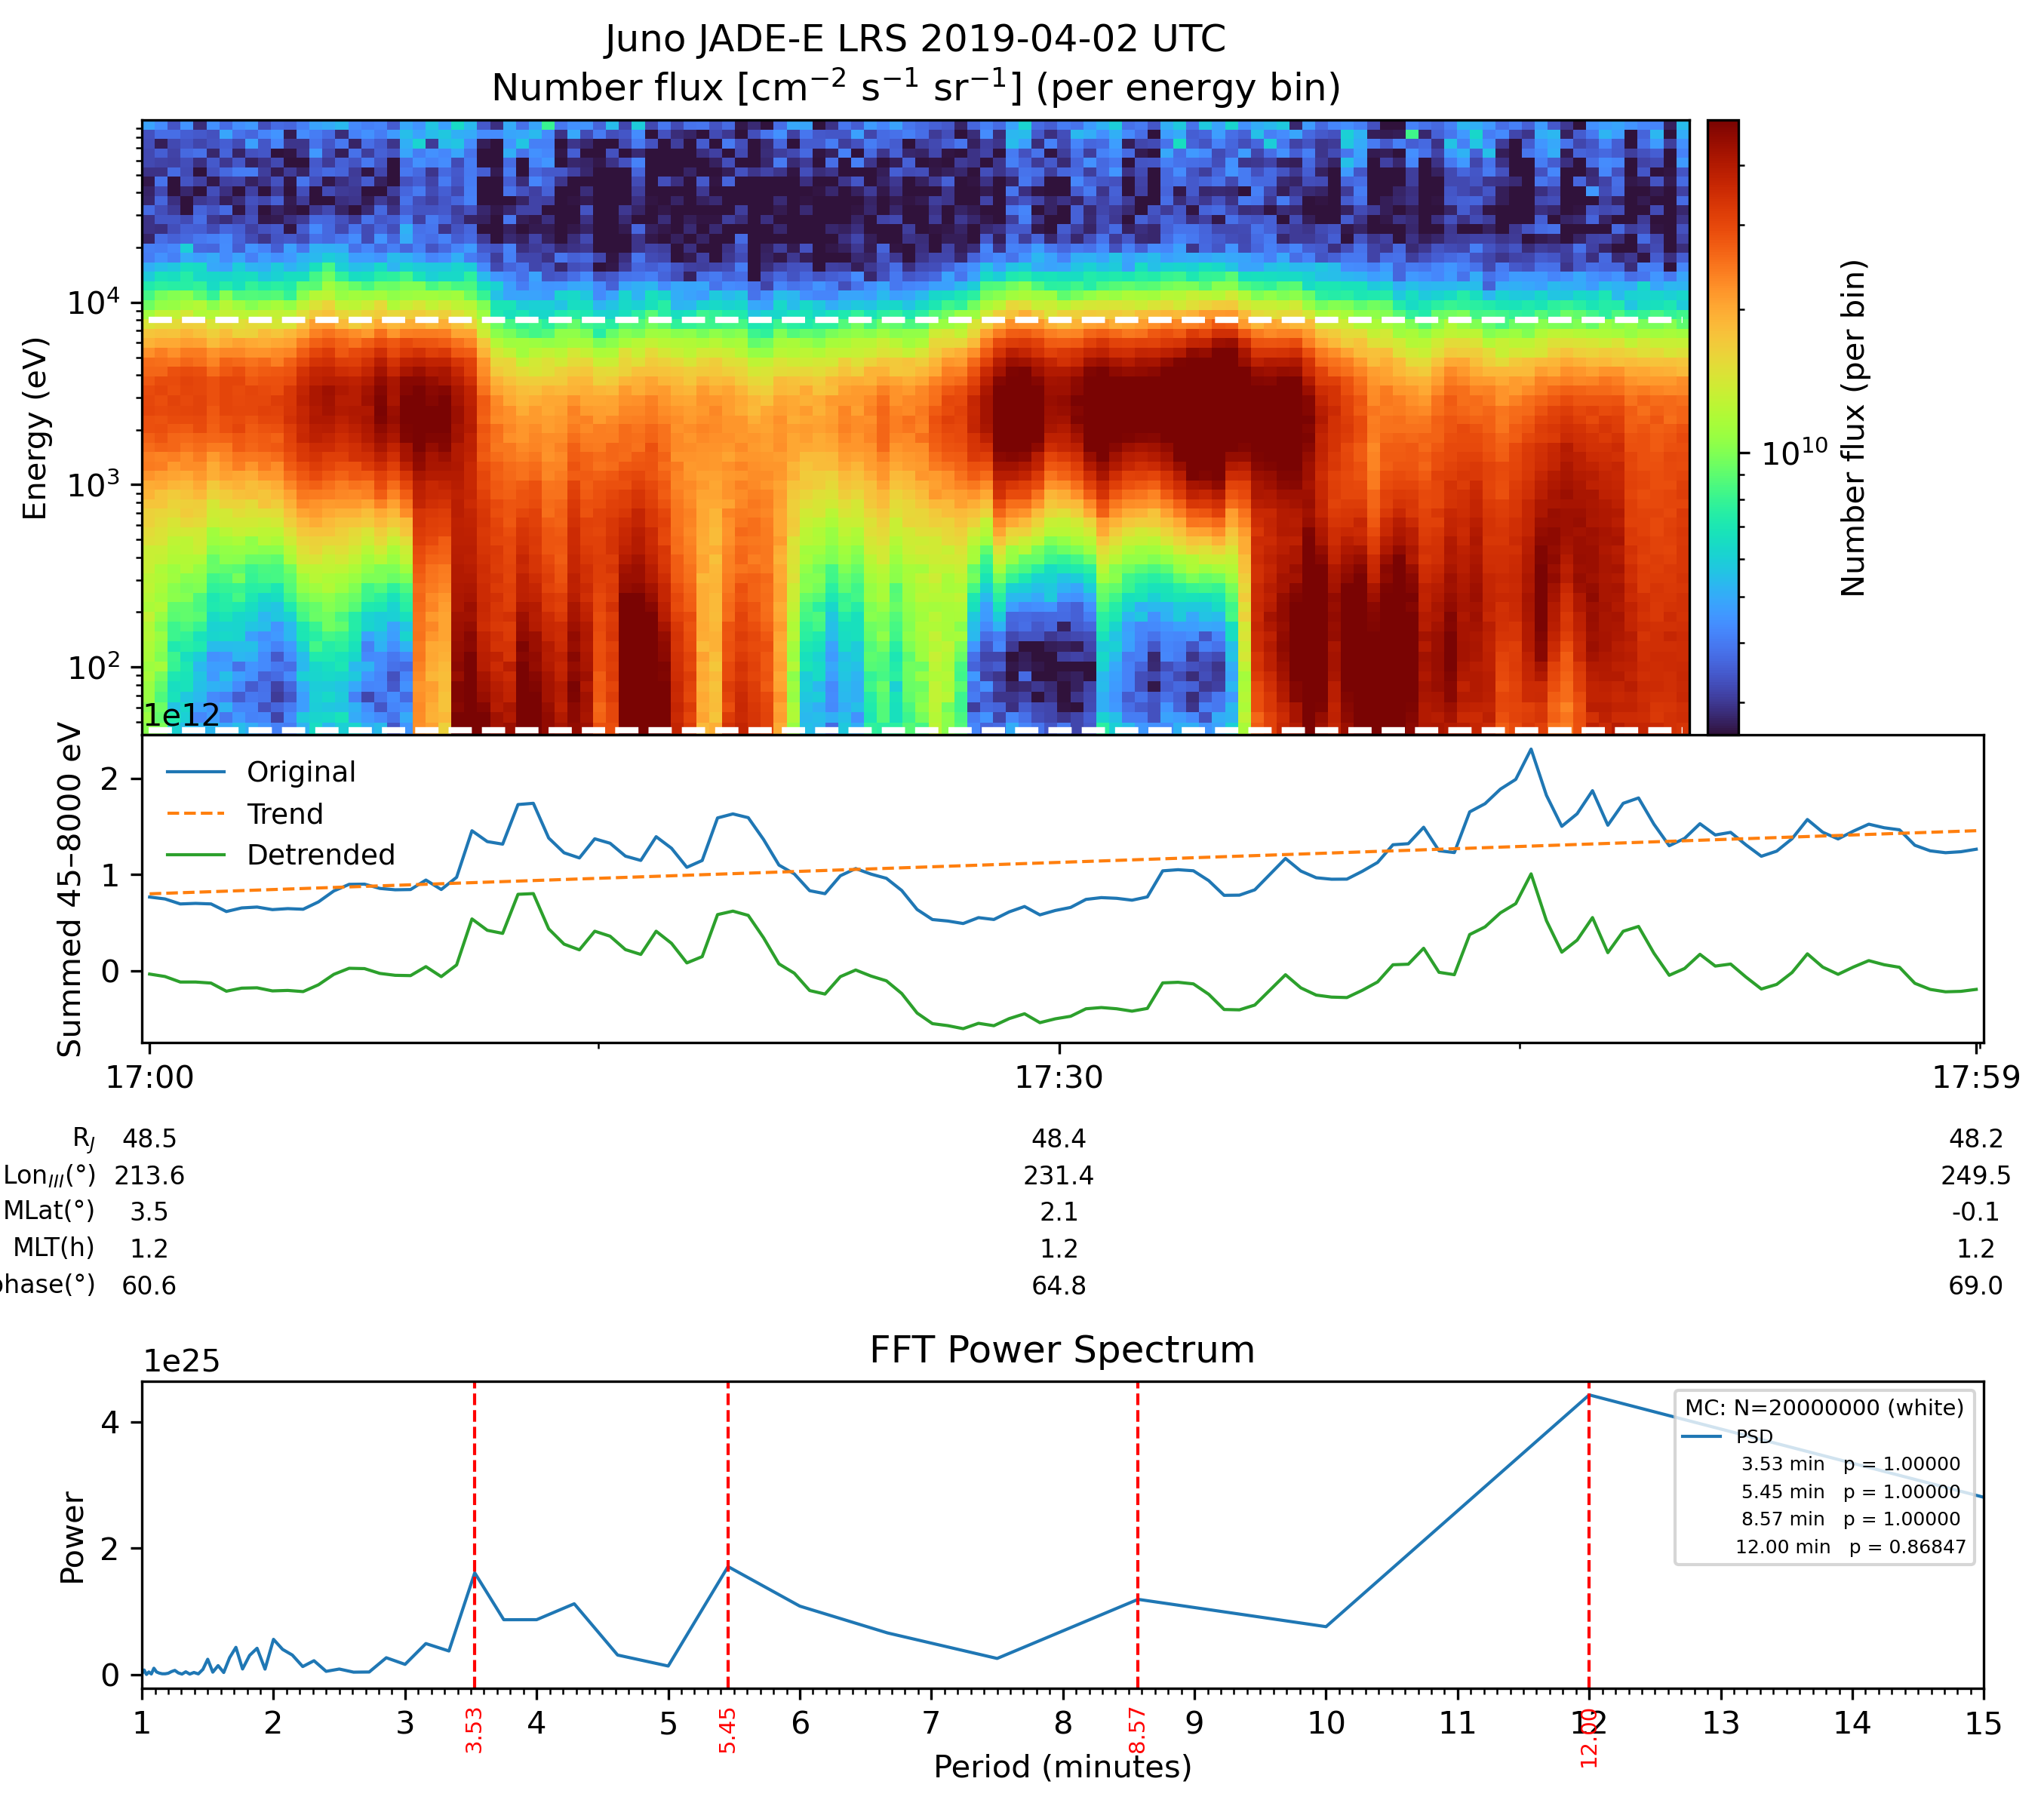

Saved f_pe series:
  Segment Analysis Figures/JAD_L50_LRS_ELC_ANY_DEF_2019092_V01_fpe_time_khz.npy
  Segment Analysis Figures/JAD_L50_LRS_ELC_ANY_DEF_2019092_V01_fpe_time_khz.csv
n_e stats [cm^-3]: median=1.01e+04, min=3.76e+03, max=2.74e+04
f_pe stats [kHz]: median=901, min=551, max=1.49e+03


In [10]:
# ================================================================
# JADE-E (PDS3 via pdr) → Segment Analysis + n_e(t) & f_pe(t)
#  - Spectrogram (log) with two horizontal energy lines
#  - Sum between lines → detrend (linear) + residual
#  - Ephemeris rows (Rj, LonIII, MLat, MLT, Io phase)
#  - FFT power spectrum with peak picking in a period window
#  - Monte-Carlo significance of FFT peaks + legend table (period, p_MC)
#  - Local electron density from JADE-E number flux (per bin) → f_pe(t)
# ================================================================

import os

# (Optional but often helpful on Apple/macOS to avoid CPU oversubscription
#  when using ProcessPoolExecutor + BLAS/FFT libs)
os.environ.setdefault("OMP_NUM_THREADS", "1")
os.environ.setdefault("OPENBLAS_NUM_THREADS", "1")
os.environ.setdefault("MKL_NUM_THREADS", "1")
os.environ.setdefault("VECLIB_MAXIMUM_THREADS", "1")
os.environ.setdefault("NUMEXPR_NUM_THREADS", "1")

import re
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import matplotlib.dates as mdates
from matplotlib.colors import LogNorm
from matplotlib.ticker import MultipleLocator, AutoMinorLocator, FixedLocator
from matplotlib.gridspec import GridSpec
from matplotlib.lines import Line2D
from scipy.signal import find_peaks
import multiprocessing as mp
from concurrent.futures import ProcessPoolExecutor
from concurrent.futures import ThreadPoolExecutor

from das2 import get_source
import pdr

# ---------------- User config ----------------
LBL_PATH        = "Data_Files/20190402 All Data/JAD_L50_LRS_ELC_ANY_DEF_2019092_V01.LBL"
OUT_DIR         = "Segment Analysis Figures"
os.makedirs(OUT_DIR, exist_ok=True)

START_TIME   = "2019-04-02T17:00:00"
END_TIME     = "2019-04-02T18:00:00"

ENERGY_MIN_EV   = 45.0
ENERGY_MAX_EV   = 8000.0

# FFT / periodogram settings (minutes)
PERIOD_MIN      = 1
PERIOD_MAX      = 15
PEAK_DETECT_MIN = 2.5
NUM_PEAKS       = 4

# Monte-Carlo settings
DO_MONTE_CARLO  = True
N_MC            = 20000000

FAP_GLOBAL      = 0.01

# Null model toggle: "phase" (recommended) or "white"
NULL_MODEL      = "white"  # "phase" or "white"

# How many worker processes to use (M3 performance cores = 10)
MC_WORKERS      = 10

# Hard-coded JADE-E 64 energy centers (eV)
ENERGY_BINS_EV = np.array([
    4.5731E+001, 5.3296E+001, 6.0349E+001, 6.8611E+001, 7.7419E+001,
    8.9858E+001, 1.0039E+002, 1.1494E+002, 1.2908E+002, 1.4807E+002,
    1.6538E+002, 1.8943E+002, 2.1210E+002, 2.4241E+002, 2.7057E+002,
    3.0856E+002, 3.4290E+002, 3.9006E+002, 4.3681E+002, 4.9299E+002,
    5.5223E+002, 6.2153E+002, 6.9798E+002, 7.8441E+002, 8.8190E+002,
    9.9458E+002, 1.1175E+003, 1.2632E+003, 1.4210E+003, 1.6066E+003,
    1.8068E+003, 2.0410E+003, 2.2617E+003, 2.5464E+003, 2.9011E+003,
    3.2921E+003, 3.7061E+003, 4.1751E+003, 4.7001E+003, 5.2996E+003,
    5.9765E+003, 6.7664E+003, 7.6124E+003, 8.5852E+003, 9.6487E+003,
    1.0927E+004, 1.2282E+004, 1.3872E+004, 1.5623E+004, 1.7610E+004,
    1.9783E+004, 2.2346E+004, 2.5209E+004, 2.8414E+004, 3.2039E+004,
    3.6123E+004, 4.0668E+004, 4.5886E+004, 5.1684E+004, 5.8298E+004,
    6.5677E+004, 7.4021E+004, 8.3346E+004, 9.3975E+004
], dtype=float)

N_E, N_LOOK = 64, 48
N_COLS = N_E * N_LOOK


# ---------------- Helpers ----------------
def energy_edges_from_centers(e):
    """Geometric midpoints; extrapolated outer edges."""
    e = np.asarray(e, float)
    mids = np.sqrt(e[:-1] * e[1:])
    return np.concatenate([[e[0]**2 / mids[0]], mids, [e[-1]**2 / mids[-1]]])


def load_jade_cube(lbl_path):
    ds = pdr.read(lbl_path)
    df = ds["TABLE"]

    t_lo = pd.to_datetime(df["DIM0_UTC_LOWER"].astype(str), format="%Y-%jT%H:%M:%S.%f", utc=False)
    t_hi = pd.to_datetime(df["DIM0_UTC_UPPER"].astype(str), format="%Y-%jT%H:%M:%S.%f", utc=False)

    pat = re.compile(r"^DATA_(\d+)$", re.IGNORECASE)
    pairs = []
    for c in df.columns:
        m = pat.match(str(c))
        if m:
            pairs.append((int(m.group(1)), c))
    pairs.sort(key=lambda x: x[0])
    data_cols = [c for _, c in pairs]
    if len(data_cols) != N_COLS:
        raise ValueError(f"Expected {N_COLS} DATA columns, got {len(data_cols)}")

    raw = df[data_cols].to_numpy(dtype=float)
    raw[raw <= -9.0e5] = np.nan

    nt = len(df)
    cube   = raw.reshape(nt, N_E, N_LOOK)  # (T, 64, 48)
    Z_mean = np.nanmean(cube, axis=2)      # (T, 64)

    mask = t_lo.notna() & t_hi.notna()
    t_lo = t_lo[mask].reset_index(drop=True)
    t_hi = t_hi[mask].reset_index(drop=True)
    Z_mean = Z_mean[mask.values, :]

    ord_idx = np.argsort(t_lo.values)
    t_lo = t_lo.iloc[ord_idx].reset_index(drop=True)
    t_hi = t_hi.iloc[ord_idx].reset_index(drop=True)
    Z_mean = Z_mean[ord_idx, :]

    t_edges   = pd.DatetimeIndex(np.concatenate([t_lo.values[:1], t_hi.values]))
    t_centers = t_lo + (t_hi - t_lo) / 2

    sorter   = np.argsort(ENERGY_BINS_EV)
    e_sorted = ENERGY_BINS_EV[sorter]
    Zp       = Z_mean[:, sorter]
    e_edges  = energy_edges_from_centers(e_sorted)

    return t_edges, t_centers, e_sorted, e_edges, Zp


def summarize_between_lines(e_sorted, Zp, emin_ev, emax_ev):
    mask_e = (e_sorted >= emin_ev) & (e_sorted <= emax_ev)
    if not np.any(mask_e):
        raise ValueError("Energy mask is empty; check ENERGY_MIN_EV/ENERGY_MAX_EV.")
    summed = np.nansum(Zp[:, mask_e], axis=1)
    return summed, mask_e


def _interpolate_nans_time(times_ns, y):
    """Time-based interpolation for NaNs (keeps sampling)."""
    y = np.asarray(y, float)
    if np.all(np.isfinite(y)):
        return y
    s = pd.Series(y, index=pd.to_datetime(times_ns))
    s = s.interpolate(method="time").bfill().ffill()
    return s.to_numpy(dtype=float)


# ---------- Fast multicore Monte-Carlo (chunk worker) ----------
def _mc_worker_chunk(args):
    """
    Worker runs n_sims surrogates locally and returns counts of (max_in_band >= peak_power).
    This avoids sending big arrays per-trial (macOS spawn-friendly).
    """
    (seed, n_sims, null_model, n, dt, idx_band, peak_powers, absXf, std_white) = args
    rng = np.random.default_rng(seed)

    counts = np.zeros(len(peak_powers), dtype=np.int64)

    # Precompute rfft length
    n_rfft = absXf.size if absXf is not None else (n // 2 + 1)

    for _ in range(n_sims):
        if null_model == "phase":
            # random phases, keep DC and (if even) Nyquist real
            phase = np.exp(1j * 2.0 * np.pi * rng.random(n_rfft))
            phase[0] = 1.0
            if n % 2 == 0:
                phase[-1] = 1.0
            surr = np.fft.irfft(absXf * phase, n=n)
        else:
            surr = rng.normal(0.0, std_white, size=n)

        fft_s = np.fft.rfft(surr)
        psd_s = (np.abs(fft_s) ** 2)

        max_in_band = psd_s[idx_band].max()
        counts += (max_in_band >= peak_powers)

    return counts, n_sims


# ---------------- Main figure ----------------
def make_segment_analysis_from_pds3(
    lbl_path=LBL_PATH,
    start_time=START_TIME,
    end_time=END_TIME,
    emin_ev=ENERGY_MIN_EV,
    emax_ev=ENERGY_MAX_EV,
    period_min=PERIOD_MIN,
    period_max=PERIOD_MAX,
    peak_detect_min=PEAK_DETECT_MIN,
    num_peaks=NUM_PEAKS,
    fap_global=FAP_GLOBAL,
    save_png=True
):
    # Load PDS3 + build arrays
    t_edges, t_centers, e_sorted, e_edges, Zp = load_jade_cube(lbl_path)

    # Window
    t0 = pd.to_datetime(start_time)
    t1 = pd.to_datetime(end_time)
    mask_t = (t_centers >= t0) & (t_centers <= t1)
    if not np.any(mask_t):
        raise ValueError("Time window selects no samples; check START_TIME/END_TIME.")

    times_win = t_centers[mask_t].to_numpy(dtype="datetime64[ns]")
    Z_win     = Zp[mask_t.values, :]

    # Sum between lines
    avg_counts, mask_e = summarize_between_lines(e_sorted, Z_win, emin_ev, emax_ev)
    avg_counts = _interpolate_nans_time(times_win, avg_counts)

    # Detrend linear
    t0c = times_win[0]
    t_sec = (times_win - t0c) / np.timedelta64(1, "s")
    if len(t_sec) < 4:
        raise ValueError("Too few samples in window for FFT/MC.")
    dt_s = float(np.median(np.diff(t_sec)))
    if not np.isfinite(dt_s) or dt_s <= 0:
        raise ValueError("Non-positive or invalid cadence; check time ordering/data gaps.")

    coeff = np.polyfit(t_sec, avg_counts, 1)
    trend = np.polyval(coeff, t_sec)
    residual = avg_counts - trend
    residual = residual - np.mean(residual)  # remove DC

    # ------------- FFT Power -------------
    n = len(residual)
    fft_y = np.fft.rfft(residual)
    psd = np.abs(fft_y) ** 2
    freqs = np.fft.rfftfreq(n, dt_s)

    # periods in minutes, avoid DC
    periods = np.full_like(freqs, np.nan, dtype=float)
    good = freqs > 0
    periods[good] = 1.0 / freqs[good] / 60.0

    mask_p  = (periods >= period_min) & (periods <= period_max) & np.isfinite(periods)
    if not np.any(mask_p):
        raise ValueError("No FFT bins in selected period range; widen PERIOD_MIN/MAX or check cadence.")

    psd_mask     = psd[mask_p]
    periods_mask = periods[mask_p]

    # Peak picking
    peaks, _ = find_peaks(psd_mask)
    if peaks.size:
        sort_idx = np.argsort(psd_mask[peaks])
        sel = peaks[sort_idx][-num_peaks:]
        sel = np.sort(sel)

        peak_periods = periods_mask[sel]
        peak_powers  = psd_mask[sel]

        keep = peak_periods >= peak_detect_min
        peak_periods = peak_periods[keep]
        peak_powers  = peak_powers[keep]

        order = np.argsort(peak_periods)
        peak_periods = peak_periods[order]
        peak_powers  = peak_powers[order]
    else:
        peak_periods = np.array([], dtype=float)
        peak_powers  = np.array([], dtype=float)

    # ------------- Monte-Carlo significance (MULTICORE) -------------
    p_values = None
    if DO_MONTE_CARLO and peak_powers.size > 0:
        null_model = NULL_MODEL.lower().strip()
        if null_model not in ("phase", "white"):
            raise ValueError("NULL_MODEL must be 'phase' or 'white'.")

        print(f"Running Monte-Carlo: N_MC={N_MC}, NULL_MODEL='{null_model}', workers={MC_WORKERS}")

        # indices into the FULL rfft PSD array for the band
        idx_band = np.where(mask_p)[0]

        # For phase surrogates: reuse amplitude spectrum (fast)
        absXf = np.abs(np.fft.rfft(residual)) if null_model == "phase" else None

        # For white surrogates: reuse std
        std_white = float(np.std(residual, ddof=1)) if null_model == "white" else 0.0

        # Split MC into chunks (one chunk per worker)
        n_workers = int(max(1, min(MC_WORKERS, os.cpu_count() or 1, N_MC)))
        base = N_MC // n_workers
        rem  = N_MC % n_workers
        sims_per_worker = [base + (1 if i < rem else 0) for i in range(n_workers)]

        ss = np.random.SeedSequence()
        child_seeds = ss.spawn(n_workers)
        seeds = [int(s.generate_state(1, dtype=np.uint64)[0]) for s in child_seeds]

        tasks = [
            (seeds[i], sims_per_worker[i], null_model, n, dt_s, idx_band, peak_powers, absXf, std_white)
            for i in range(n_workers)
        ]

        total_counts = np.zeros(len(peak_powers), dtype=np.int64)
        total_sims = 0

        # ---- ProcessPool in notebooks needs fork on macOS ----
        # If fork isn't available/allowed, fall back to threads.
        try:
            ctx = mp.get_context("fork")
            use_processes = True
        except Exception:
            ctx = None
            use_processes = False

        Executor = ProcessPoolExecutor if use_processes else ThreadPoolExecutor
        ex_kwargs = {"max_workers": n_workers}
        if use_processes:
            ex_kwargs["mp_context"] = ctx

        with Executor(**ex_kwargs) as pool:
            for counts, n_done in pool.map(_mc_worker_chunk, tasks):
                total_counts += counts
                total_sims += n_done

        p_values = total_counts / float(total_sims)

        print("Monte-Carlo peak significance (global; max power in band):")
        for per, P, p in zip(peak_periods, peak_powers, p_values):
            print(f"  Peak at {per:5.2f} min: power={P:9.3g}, p_MC={p:8.5f}")
        print(f"Peaks with p_MC < {fap_global} are 'significant' at that global level.")
    else:
        if DO_MONTE_CARLO:
            print("No peaks found in selected band; Monte-Carlo skipped.")

    # ------------- Plot -------------
    basename = os.path.splitext(os.path.basename(lbl_path))[0]
    fig = plt.figure(figsize=(10.5, 9), dpi=300)
    outer_gs = GridSpec(2, 1, figure=fig, height_ratios=[3, 1], hspace=0.55)
    inner_gs = outer_gs[0].subgridspec(2, 1, height_ratios=[2, 1], hspace=0.0)

    ax_spec = fig.add_subplot(inner_gs[0])
    ax_avg  = fig.add_subplot(inner_gs[1], sharex=ax_spec)
    ax_fft  = fig.add_subplot(outer_gs[1])

    # Spectrogram edges for the window
    idx0 = np.where(t_centers.to_numpy() >= times_win[0])[0][0]
    idx1 = np.where(t_centers.to_numpy() <= times_win[-1])[0][-1]
    t_edges_win = t_edges[idx0: idx1 + 2]

    Zpos = Z_win[np.isfinite(Z_win) & (Z_win > 0)]
    if Zpos.size == 0:
        raise RuntimeError("No positive values to plot.")
    vmin, vmax = np.nanpercentile(Zpos, [5, 95])
    vmin = max(vmin, np.nextafter(0.0, 1.0))

    pcm = ax_spec.pcolormesh(
        t_edges_win, e_edges, Z_win.T, shading="auto",
        norm=LogNorm(vmin=vmin, vmax=vmax), cmap="turbo"
    )
    ax_spec.set_yscale("log")
    ax_spec.set_facecolor("black")
    ax_spec.plot([times_win[0], times_win[-1]], [emin_ev, emin_ev], "--w", lw=2)
    ax_spec.plot([times_win[0], times_win[-1]], [emax_ev, emax_ev], "--w", lw=2)
    ax_spec.set_ylabel("Energy (eV)")
    ax_spec.set_title(
        f"Juno JADE-E LRS {pd.to_datetime(START_TIME).strftime('%Y-%m-%d')} UTC\n"
        + r"Number flux [$\mathrm{cm^{-2}\ s^{-1}\ sr^{-1}}$] (per energy bin)"
    )
    ax_spec.tick_params(labelbottom=False)
    fig.colorbar(pcm, ax=ax_spec, pad=0.01, label="Number flux (per bin)")

    # Summed series + trend + residual
    ax_avg.plot(times_win, avg_counts, label="Original", color="C0", lw=1.0)
    ax_avg.plot(times_win, trend, linestyle="--", color="C1", label="Trend", lw=1.0)
    ax_avg.plot(times_win, residual, color="C2", label="Detrended", lw=1.0)
    ax_avg.set_ylabel(f"Summed {emin_ev:.0f}–{emax_ev:.0f} eV")
    ax_avg.legend(frameon=False, fontsize=9)

    # Ticks
    total_hours = (times_win[-1] - times_win[0]) / np.timedelta64(1, "h")
    tick_interval_h = 1 if total_hours <= 12 else 2
    eph_step = np.timedelta64(30, "m") if total_hours <= 4 else np.timedelta64(int(tick_interval_h), "h")

    t0h = times_win[0].astype("datetime64[h]")
    t1h = times_win[-1].astype("datetime64[h]") + np.timedelta64(1, "h")
    maj = np.arange(t0h, t1h, eph_step)
    all_ticks = np.unique(np.concatenate(([times_win[0]], maj, [times_win[-1]])))
    py_ticks  = [pd.to_datetime(t).to_pydatetime() for t in all_ticks]
    tick_nums = mdates.date2num(py_ticks)

    ax_avg.xaxis.set_major_locator(FixedLocator(tick_nums))
    ax_avg.xaxis.set_major_formatter(mdates.DateFormatter("%H:%M"))
    ax_avg.xaxis.set_minor_locator(mdates.MinuteLocator(interval=10))
    plt.setp(ax_avg.get_xticklabels(which="major"), rotation=0)

    # Ephemeris rows
    eph_src = get_source("tag:das2.org,2012:site:/uiowa/juno/ephemeris/jovicentric/das2")
    ds_eph = eph_src.get({"time": (START_TIME, END_TIME, int(max(1, round(dt_s))))})[0]

    eph_t  = ds_eph["time"]["center"].array
    rad    = ds_eph["radius"]["center"].array
    lon3   = ds_eph["long"]["center"].array
    mlatE  = ds_eph["mlat"]["center"].array
    mltE   = ds_eph["mlt"]["center"].array
    ioE    = ds_eph["io_phase"]["center"].array
    if getattr(mltE, "dtype", None) is not None and mltE.dtype.kind == "m":
        mltE = (mltE / np.timedelta64(1, "h")).astype(float)

    row_lbls   = ["R$_J$", "Lon$_{III}$(°)", "MLat(°)", "MLT(h)", "Io phase(°)"]
    row_arrays = [rad, lon3, mlatE, mltE, ioE]
    row_spacing = 0.12

    idxs = [int(np.argmin(np.abs(eph_t - np.datetime64(t)))) for t in all_ticks]
    for j, (label, arr) in enumerate(zip(row_lbls, row_arrays)):
        off = -row_spacing * (j + 2)
        sax = ax_avg.secondary_xaxis(off, functions=(lambda x: x, lambda x: x))
        sax.xaxis.set_major_locator(FixedLocator(tick_nums))
        vals = arr[idxs]
        sax.set_xticklabels([f"{float(v):.1f}" for v in vals], rotation=0, va="top", fontsize=8)
        sax.spines["bottom"].set_visible(False)
        sax.tick_params(axis="x", length=0)
        sax.xaxis.set_ticks_position("bottom")
        sax.xaxis.set_label_position("bottom")
        txt = sax.set_xlabel(label, fontsize=8, labelpad=-8.5, loc="left")
        txt.set_x(-0.025)
        txt.set_ha("right")

    # FFT plot + peak lines
    psd_line, = ax_fft.plot(periods_mask, psd_mask, color="C0", linewidth=1, label="PSD")

    for p in peak_periods:
        ax_fft.axvline(p, ls="--", color="red", lw=1)
        ax_fft.text(
            p, -0.05, f"{p:.2f}",
            transform=ax_fft.get_xaxis_transform(),
            rotation=90, va="top", ha="center",
            color="red", fontsize=7
        )

    ax_fft.set_xlim(period_min, period_max)
    ax_fft.set_xlabel("Period (minutes)")
    ax_fft.set_ylabel("Power")
    ax_fft.set_title("FFT Power Spectrum")
    ax_fft.xaxis.set_major_locator(MultipleLocator(1))
    ax_fft.xaxis.set_minor_locator(AutoMinorLocator(10))

    # Legend-as-table
    handles = [psd_line]
    labels  = ["PSD"]
    if p_values is not None and p_values.size > 0:
        for per, p in zip(peak_periods, p_values):
            handles.append(Line2D([], [], color='none'))
            labels.append(f"{per:5.2f} min   p = {p:7.5f}")
        legend_title = f"MC: N={N_MC} ({NULL_MODEL})"
    else:
        legend_title = None

    ax_fft.legend(
        handles, labels, loc='upper right',
        frameon=True, title=legend_title,
        fontsize=6, title_fontsize=7
    )

    # align X ticks on spectrogram
    ax_spec.xaxis.set_major_locator(FixedLocator(tick_nums))
    ax_spec.xaxis.set_major_formatter(mdates.DateFormatter("%H:%M"))
    ax_spec.xaxis.set_minor_locator(mdates.MinuteLocator(interval=15))

    fig.tight_layout()

    if save_png:
        out = os.path.join(OUT_DIR, f"{basename}_segment_analysis.png")
        fig.savefig(out, dpi=300, bbox_inches="tight")
        print(f"Saved → {out}")

    plt.show()

    # ===========================================
    # POST: n_e(t) from JADE-E number flux (per bin) → f_pe(t)
    # ===========================================

    E_ev   = e_sorted.astype(float)
    dE_ev  = np.diff(e_edges).astype(float)  # (64,)

    assert Z_win.shape[1] == dE_ev.size == e_sorted.size == 64, \
        f"Shape mismatch: Z_win {Z_win.shape}, dE {dE_ev.size}, e_sorted {e_sorted.size}"

    j_per_eV = Z_win / dE_ev[np.newaxis, :]

    me = 9.10938356e-31
    qe = 1.602176634e-19
    v_cms = np.sqrt(2.0 * (E_ev * qe) / me) * 100.0

    emask = (E_ev >= 50.0) & (E_ev <= 20000.0)
    integrand = j_per_eV[:, emask] / v_cms[np.newaxis, emask]
    ne_cm3 = 4.0 * np.pi * np.trapz(integrand, x=E_ev[emask], axis=1)

    fpe_hz  = 8980.0 * np.sqrt(np.clip(ne_cm3, 0, None))
    fpe_khz = fpe_hz / 1e3

    t_unix = (times_win.astype('datetime64[ns]').astype('int64') / 1e9).astype(float)
    fpe_2d = np.column_stack([t_unix, fpe_khz])

    base = os.path.splitext(os.path.basename(lbl_path))[0]
    out_npy = os.path.join(OUT_DIR, f"{base}_fpe_time_khz.npy")
    out_csv = os.path.join(OUT_DIR, f"{base}_fpe_time_khz.csv")
    np.save(out_npy, fpe_2d)
    np.savetxt(out_csv, fpe_2d, delimiter=",", header="unix_time_s,f_pe_kHz", comments="")

    print(f"Saved f_pe series:\n  {out_npy}\n  {out_csv}")
    print(f"n_e stats [cm^-3]: median={np.nanmedian(ne_cm3):.3g}, "
          f"min={np.nanmin(ne_cm3):.3g}, max={np.nanmax(ne_cm3):.3g}")
    print(f"f_pe stats [kHz]: median={np.nanmedian(fpe_khz):.3g}, "
          f"min={np.nanmin(fpe_khz):.3g}, max={np.nanmax(fpe_khz):.3g}")


# ---------------- Run ----------------
if __name__ == "__main__":
    make_segment_analysis_from_pds3()

Tick interval (h): 1
Running Monte-Carlo with N_MC = 10000 surrogates using NULL_MODEL = 'white' ...

Monte-Carlo peak significance (global, based on max power in band):
  Peak at  6.79 min: power =  1.4e-14, p_MC =  0.0000
  Peak at  7.34 min: power = 9.29e-15, p_MC =  0.0000
  Peak at  8.99 min: power = 1.59e-14, p_MC =  0.0000
  Peak at 12.85 min: power = 1.49e-14, p_MC =  0.0000

Peaks with p_MC < 0.01 are 'significant' at that level.


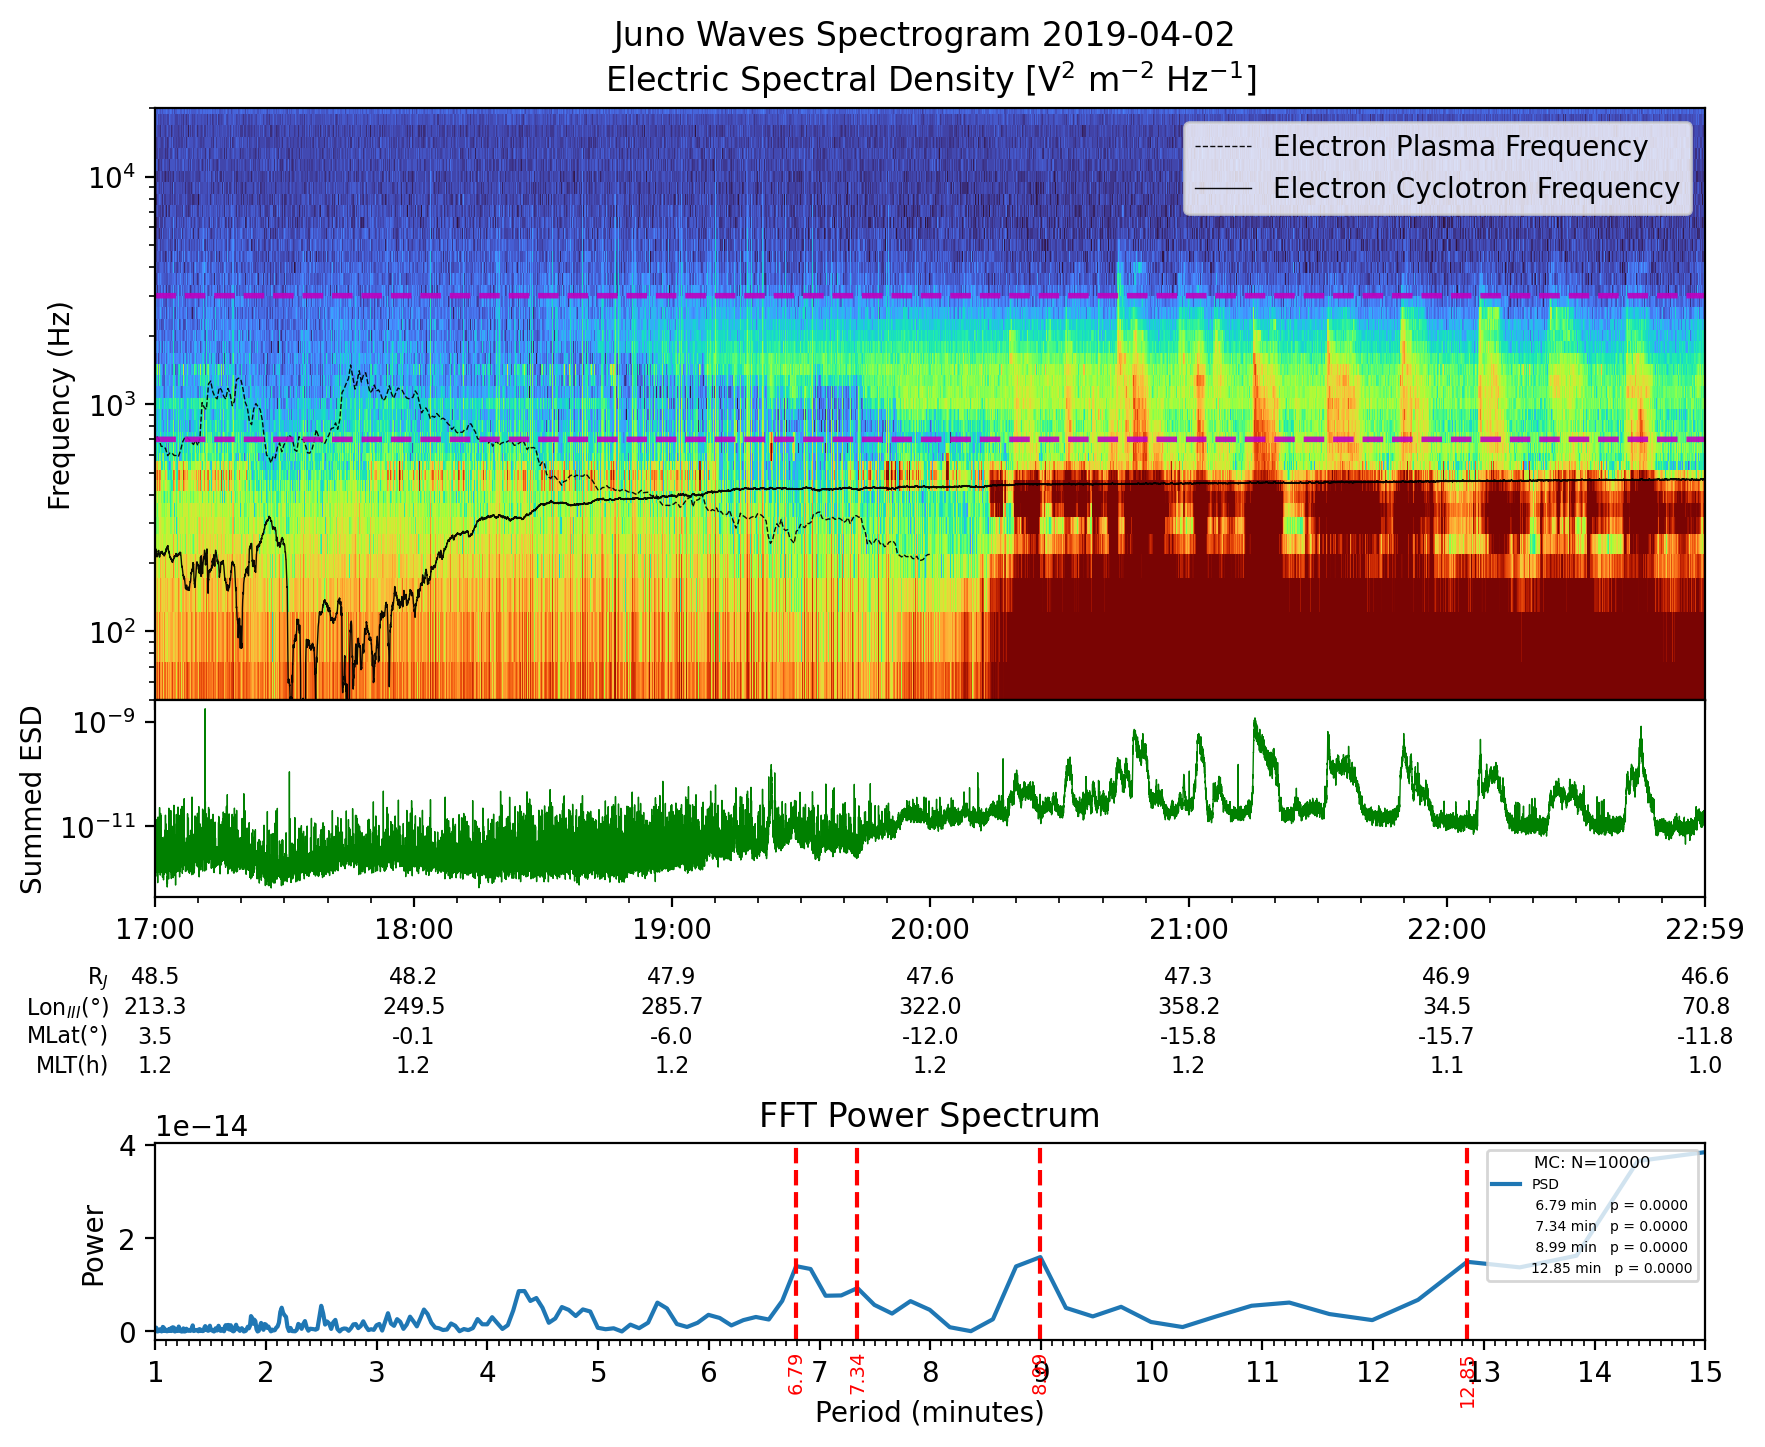

In [52]:
import numpy as np
import matplotlib.pyplot as plt
import matplotlib.dates as mdates
from matplotlib.colors import LogNorm
from matplotlib.ticker import MultipleLocator, AutoMinorLocator
from matplotlib.lines import Line2D
from scipy.signal import find_peaks
from das2 import get_source
import matplotlib.patheffects as pe
from matplotlib.gridspec import GridSpec
import pandas as pd
import das2
from concurrent.futures import ProcessPoolExecutor
import itertools

# —————————————————————————————————————————————
# CONFIGURATION
SERVER_URL      = "tag:das2.org,2012:site:/uiowa/juno/wav/survey/das2"
START_TIME      = "2019-04-02T17:00:00"
END_TIME        = "2019-04-02T23:00:00"

# Whistler band for summation (Hz)
WHIS_MIN        = 700
WHIS_MAX        = 3000

# FFT / PSD parameters
PERIOD_MIN      = 1      # minutes
PERIOD_MAX      = 15     # minutes
PEAK_DETECT_MIN = 2.5    # only label peaks ≥ this period
NUM_PEAKS       = 4      # top N peaks to report

# Monte-Carlo settings
DO_MONTE_CARLO  = True   # set False if you want to disable
N_MC            = 10000   # number of surrogate realizations

# Null model toggle: "phase" (recommended) or "white"
NULL_MODEL      = "white"   # or "white"

# For interpretation only: "significant" if p_MC < FAP_GLOBAL
FAP_GLOBAL      = 0.01   # e.g. 1% global false-alarm probability

# —————————————————————————————————————————————
# 1) Fetch whistler data
source = get_source(SERVER_URL)
whis, _, _, _ = source.get({
    'time': (START_TIME, END_TIME)
})

# 2) Extract time, frequency, and spectral density
def extract_arrays(d):
    f_arr = d['frequency']['center'].array
    freqs = f_arr[0, :] if f_arr.ndim > 1 else f_arr
    t_arr = d['Time']['center'].array
    times = t_arr[:, 0] if t_arr.ndim > 1 else t_arr
    spec  = d['spec_dens']['center'].array.squeeze()
    if spec.shape[1] != freqs.size:
        spec = spec.T
    return np.array(times, dtype='datetime64[ms]'), freqs, spec

times, freqs, spec = extract_arrays(whis)

total_hours    = (times[-1] - times[0]) / np.timedelta64(1, 'h')
tick_interval_h = 1 if total_hours <= 12 else 2
print("Tick interval (h):", tick_interval_h)

# 3) Sum spectral density across the chosen band
mask_band = (freqs >= WHIS_MIN) & (freqs <= WHIS_MAX)
sum_sd    = spec[:, mask_band].sum(axis=1)

# 4) Build time axis in seconds for detrending
t0    = times[0]
t_sec = (times - t0) / np.timedelta64(1, 's')
dt    = np.median(np.diff(t_sec))  # sampling step in seconds

# 5) Detrend: fit and remove linear trend
coeff   = np.polyfit(t_sec, sum_sd, 1)
trend   = np.polyval(coeff, t_sec)
resid   = sum_sd - trend

# —————————————————————————————————————————————
# 6) FFT & Power Spectral Density
n        = len(resid)
fft_y    = np.fft.rfft(resid)
psd      = np.abs(fft_y)**2            # raw power (arbitrary units)
f_fft    = np.fft.rfftfreq(n, dt)      # Hz

# Build periods array safely (avoid division by zero at f=0)
periods = np.empty_like(f_fft)
periods[0] = np.inf
periods[1:] = 1.0 / f_fft[1:] / 60.0   # minutes

# Restrict to desired period range
mask_p     = (periods >= PERIOD_MIN) & (periods <= PERIOD_MAX)
psd_m      = psd[mask_p]
periods_m  = periods[mask_p]

# 7) Peak detection in the FFT spectrum
peaks, _ = find_peaks(psd_m)
if len(peaks) > 0:
    # pick top NUM_PEAKS peaks by power
    sort_idx     = np.argsort(psd_m[peaks])
    sel          = peaks[sort_idx][-NUM_PEAKS:]
    peak_periods = periods_m[sel]
    peak_powers  = psd_m[sel]

    # Enforce minimum period if desired
    keep = peak_periods >= PEAK_DETECT_MIN
    peak_periods = peak_periods[keep]
    peak_powers  = peak_powers[keep]

    # Sort peaks by period for nicer plotting/table
    order = np.argsort(peak_periods)
    peak_periods = peak_periods[order]
    peak_powers  = peak_powers[order]
else:
    peak_periods = np.array([])
    peak_powers  = np.array([])

# —————————————————————————————————————————————
# 8) Surrogate generator with null-model toggle

def generate_surrogate(x, null_model="phase", rng=None):
    """
    Generate a surrogate series under a chosen null model.

    null_model:
      - "phase": phase-randomised surrogate, preserving power spectrum
      - "white": Gaussian white noise with same variance as x
    """
    if rng is None:
        rng = np.random.default_rng()

    x = np.asarray(x, float)
    n = len(x)

    if null_model.lower() == "phase":
        Xf = np.fft.rfft(x)
        phase = np.exp(1j * 2.0 * np.pi * rng.random(len(Xf)))
        phase[0] = 1.0
        if n % 2 == 0:
            phase[-1] = 1.0
        Xf_rand = np.abs(Xf) * phase
        return np.fft.irfft(Xf_rand, n=n)

    elif null_model.lower() == "white":
        std = np.nanstd(x, ddof=1)
        return rng.normal(0.0, std, size=n)

    else:
        raise ValueError(f"Unknown NULL_MODEL '{null_model}'. Use 'phase' or 'white'.")



# Helper for parallel Monte-Carlo (one surrogate max power)
def _mc_max_peak(seed, resid_local, mask_p_local, null_model_local):
    """Return max PSD within mask for one surrogate (for process pool)."""
    rng = np.random.default_rng(seed)
    surr = generate_surrogate(resid_local, null_model_local, rng=rng)
    fft_s = np.fft.rfft(surr)
    psd_s = np.abs(fft_s)**2
    psd_s_m = psd_s[mask_p_local]
    return psd_s_m.max()

p_values = None

if DO_MONTE_CARLO and len(peak_powers) > 0:
    print(f"Running Monte-Carlo with N_MC = {N_MC} surrogates "
          f"using NULL_MODEL = '{NULL_MODEL}' ...")
    n_workers = min(5, N_MC)
    seeds = np.random.SeedSequence().spawn(N_MC)
    seed_ints = [int(s.generate_state(1, dtype=np.uint64)[0]) for s in seeds]
    chunksize = max(1, N_MC // (n_workers * 4))

    with ProcessPoolExecutor(max_workers=n_workers) as pool:
        mc_max_peaks = np.fromiter(
            pool.map(
                _mc_max_peak,
                seed_ints,
                itertools.repeat(resid),
                itertools.repeat(mask_p),
                itertools.repeat(NULL_MODEL),
                chunksize=chunksize,
            ),
            dtype=float,
            count=len(seed_ints),
        )

    # p-value for each observed peak: fraction of MC maxima ≥ observed power
    p_values = np.array([np.mean(mc_max_peaks >= P) for P in peak_powers])

    print("
Monte-Carlo peak significance (global, based on max power in band):")
    for per, P, p in zip(peak_periods, peak_powers, p_values):
        print(f"  Peak at {per:5.2f} min: power = {P:8.3g}, p_MC = {p:7.4f}")

    print(f"
Peaks with p_MC < {FAP_GLOBAL} are 'significant' at that level.")
else:
    if DO_MONTE_CARLO:
        print("No peaks found in the selected band; Monte-Carlo skipped.")
# —————————————————————————————————————————————
# 9) Plot: nested GridSpec

fig = plt.figure(figsize=(10, 8), dpi=200)
outer_gs = GridSpec(2, 1, figure=fig, height_ratios=[4, 1], hspace=0.5)

# top “compound” axes: a 2×1 inside the first slot of outer_gs
inner_gs = outer_gs[0].subgridspec(2, 1, height_ratios=[3, 1], hspace=0.0)
ax_spec = fig.add_subplot(inner_gs[0])
ax_ts   = fig.add_subplot(inner_gs[1], sharex=ax_spec)

# bottom FFT axis in the second slot of outer_gs
ax_fft  = fig.add_subplot(outer_gs[1])

# a) Spectrogram
pcm = ax_spec.pcolormesh(
    times, freqs, spec.T,
    norm=LogNorm(vmin=1e-14, vmax=1e-9), cmap='turbo', shading='nearest'
)

# ---- Overlay electron plasma frequency (from JADE-E) on the spectrogram ----
FPE_PATH = "Segment Analysis Figures/JAD_L50_LRS_ELC_ANY_DEF_2019092_V01_fpe_time_khz.npy"

try:
    fpe_2d = np.load(FPE_PATH)                     # shape (N, 2)
    t_unix = fpe_2d[:, 0].astype(float)            # seconds since epoch (UTC)
    f_khz  = fpe_2d[:, 1].astype(float)            # kHz or Hz, depending on file

    # Convert to datetime64[ms] so it matches your 'times' dtype
    t_fpe = t_unix.astype("datetime64[s]").astype("datetime64[ms]")
    f_hz  = f_khz  # adjust to *1e3 if file is in kHz

    mask_fpe = (t_fpe >= times[0]) & (t_fpe <= times[-1]) & np.isfinite(f_hz)
    ax_spec.plot(
        t_fpe[mask_fpe], f_hz[mask_fpe],
        lw=0.5, color='black', alpha=0.95,
        label="Electron Plasma Frequency", linestyle='--'
    )

except FileNotFoundError:
    print(f"Could not find {FPE_PATH}. Generate it from the JADE–E script first.")

ax_spec.set_yscale('log')
ax_spec.set_facecolor('black')
ax_spec.plot(times, [WHIS_MIN]*len(times), '--m', lw=2, alpha=0.9)
ax_spec.plot(times, [WHIS_MAX]*len(times), '--m', lw=2, alpha=0.9)
ax_spec.set_ylabel('Frequency (Hz)')
ax_spec.set_title(
    f'Juno Waves Spectrogram {pd.to_datetime(START_TIME).strftime("%Y-%m-%d")} \n'
    'Electric Spectral Density [V$^2$ m$^{-2}$ Hz$^{-1}$]'
)

# Electron cyclotron frequency overlay
efc_source = das2.get_source('tag:das2.org,2012:site:/uiowa/juno/fgm/electroncyclotron/das2')
ds_efc = efc_source.get({'time': (START_TIME, END_TIME)})[0]
efc_freq = ds_efc['fce']['center'].array
efc_time = ds_efc['time']['center'].array
ax_spec.plot(efc_time, efc_freq, color='black', linewidth=0.5, alpha=0.95, label='Electron Cyclotron Frequency')
ax_spec.set_ylim(5e1, 2e4)

ax_spec.tick_params(labelbottom=False)
ax_spec.legend(loc='upper right', frameon=True)
# b) Summed time series (shares x with spec only)
ax_ts.plot(times, sum_sd, linewidth=0.5, color='green')
ax_ts.set_ylabel('Summed ESD')
ax_ts.set_xlim(times[0], times[-1])
ax_ts.set_yscale('log')

major = mdates.HourLocator(interval=tick_interval_h)
minor = mdates.MinuteLocator(interval=10)
fmt   = mdates.DateFormatter('%H:%M')
ax_ts.xaxis.set_major_locator(major)
ax_ts.xaxis.set_minor_locator(minor)
ax_ts.xaxis.set_major_formatter(fmt)

# ─── Ephemeris rows below the summed time series ─────────────────────────────

from matplotlib.ticker import FixedLocator

eph_src = get_source('tag:das2.org,2012:site:/uiowa/juno/ephemeris/jovicentric/das2')
ds_eph  = eph_src.get({'time': (START_TIME, END_TIME, int(dt))})[0]

rad   = ds_eph['radius']['center'].array
lon3  = ds_eph['long']['center'].array
mlatE = ds_eph['mlat']['center'].array
mltE  = ds_eph['mlt']['center'].array
if mltE.dtype.kind == 'm':
    mltE = (mltE / np.timedelta64(1, 'h')).astype(float)

# build tick list including endpoints
t0h = times[0].astype('datetime64[h]')
t1h = times[-1].astype('datetime64[h]') + np.timedelta64(1, 'h')
maj_ticks = np.arange(t0h, t1h, np.timedelta64(tick_interval_h, 'h'))

all_ticks = np.unique(np.concatenate(([times[0]], maj_ticks, [times[-1]])))
py_ticks  = [t.tolist() for t in all_ticks]
all_tick_nums = mdates.date2num(py_ticks)

ax_ts.xaxis.set_major_locator(FixedLocator(all_tick_nums))
ax_ts.xaxis.set_major_formatter(fmt)

idx_eph = [np.argmin(np.abs(times - t64)) for t64 in all_ticks]

row_lbls    = ["R$_J$", "Lon$_{III}$(°)", "MLat(°)", "MLT(h)"]
row_arrays  = [rad, lon3, mlatE, mltE]
row_spacing = 0.15

for j, (label, arr) in enumerate(zip(row_lbls, row_arrays)):
    off = -row_spacing * (j + 2)
    sax = ax_ts.secondary_xaxis(off, functions=(lambda x: x, lambda x: x))
    sax.xaxis.set_major_locator(FixedLocator(all_tick_nums))
    vals = arr[idx_eph]
    sax.set_xticklabels([f"{v:.1f}" for v in vals],
                        rotation=0, va='top', fontsize=8)
    sax.spines['bottom'].set_visible(False)
    sax.tick_params(axis='x', length=0)
    sax.xaxis.set_ticks_position('bottom')
    sax.xaxis.set_label_position('bottom')
    txt = sax.set_xlabel(label, fontsize=8, labelpad=-8.5, loc='left')
    txt.set_x(-0.03)
    txt.set_ha('right')

# c) FFT Power Spectrum (independent x-axis)
psd_line, = ax_fft.plot(periods_m, psd_m, label='PSD')

for p in peak_periods:
    ax_fft.axvline(p, ls='--', color='red')
    ax_fft.text(
        p,
        -0.05,
        f'{p:.2f}',
        transform=ax_fft.get_xaxis_transform(),
        rotation=90,
        va='top',
        ha='center',
        color='red',
        fontsize=7
    )

ax_fft.set_xlim(PERIOD_MIN, PERIOD_MAX)
ax_fft.set_xlabel('Period (minutes)')
ax_fft.set_ylabel('Power')
ax_fft.set_title('FFT Power Spectrum')

# Legend-as-table
handles = [psd_line]
labels  = ["PSD"]

if p_values is not None and len(p_values) > 0:
    for per, p in zip(peak_periods, p_values):
        row_handle = Line2D([], [], color='none')
        handles.append(row_handle)
        labels.append(f"{per:5.2f} min   p = {p:6.4f}")

    legend_title = f"MC: N={N_MC}"
else:
    legend_title = None

ax_fft.legend(
    handles,
    labels,
    loc='upper right',
    frameon=True,
    title=legend_title,
    fontsize=5,
    title_fontsize=6
)

ax_fft.xaxis.set_major_locator(MultipleLocator(1))
ax_fft.xaxis.set_minor_locator(AutoMinorLocator(10))

plt.show()


Running Monte-Carlo with N_MC = 10000 surrogates using NULL_MODEL = 'white' ...

Monte-Carlo peak significance (global, based on max power in band):
  Peak at  7.83 min: power = 1.09e+08, p_MC =  0.0000
  Peak at 12.41 min: power = 9.42e+07, p_MC =  0.0000
  Peak at 18.95 min: power = 1.94e+08, p_MC =  0.0000

Peaks with p_MC < 0.01 are 'significant' at that level.


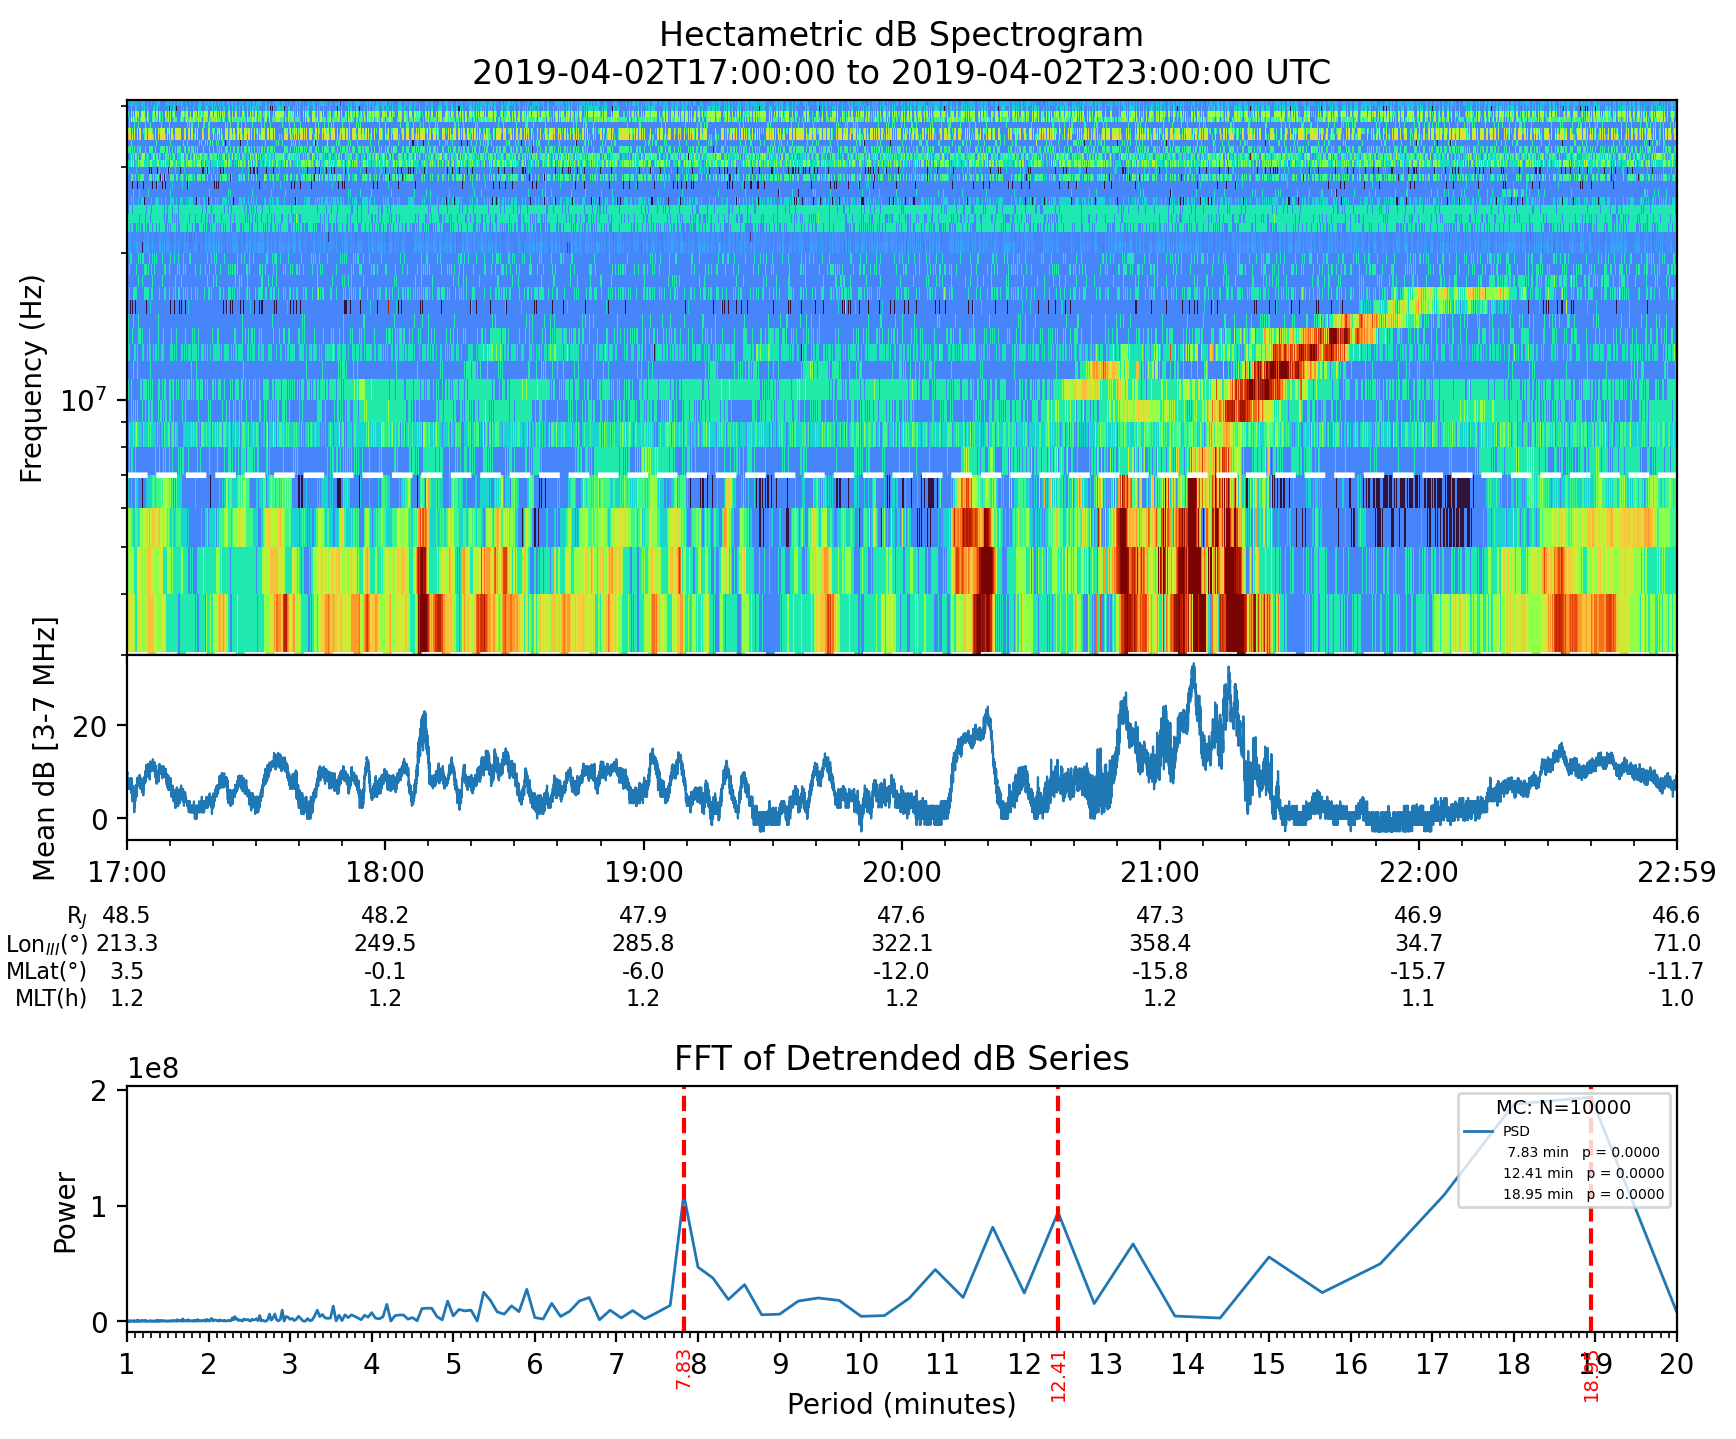

In [51]:
import numpy as np
import matplotlib.pyplot as plt
import matplotlib.dates as mdates
from matplotlib.colors import LogNorm
from matplotlib.ticker import MultipleLocator, AutoMinorLocator, FixedLocator
from matplotlib.gridspec import GridSpec
from matplotlib.lines import Line2D
from scipy.signal import find_peaks
from das2 import get_source

# —————————————————————————————————————————————
# CONFIGURATION
SERVER_URL      = "tag:das2.org,2012:site:/uiowa/juno/wav/survey/das2"
START_TIME      = "2019-04-02T17:00:00"
END_TIME        = "2019-04-02T23:00:00"

DB_VMIN         = -5
DB_VMAX         = 25

HECT_MIN        = 3e6
HECT_MAX        = 7e6

PERIOD_MIN      = 1
PERIOD_MAX      = 20
PEAK_DETECT_MIN = 2.5
NUM_PEAKS       = 3

DO_MONTE_CARLO  = True
N_MC            = 10000
FAP_GLOBAL      = 0.01

# Null model toggle: "phase" (recommended) or "white"
NULL_MODEL      = "white"   # or "white"

# —————————————————————————————————————————————
# 1) Fetch Hectametric data
source = get_source(SERVER_URL)
_, _, _, hect = source.get({'time': (START_TIME, END_TIME)})

# 2) Extract arrays
def extract_arrays(d):
    f_arr = d['frequency']['center'].array
    freqs = f_arr[0, :] if f_arr.ndim > 1 else f_arr
    t_arr = d['Time']['center'].array
    times = t_arr[:, 0] if t_arr.ndim > 1 else t_arr
    S = d['spec_dens']['center'].array.squeeze()
    if S.shape[1] != freqs.size:
        S = S.T
    return np.array(times, dtype='datetime64[ms]'), freqs, S

times, freqs, spec = extract_arrays(hect)

total_hours     = (times[-1] - times[0]) / np.timedelta64(1, 'h')
tick_interval_h = 1 if total_hours <= 12 else 2

# 3) dB above 10th-percentile background
S_clean  = spec.astype(float)
mask_bad = (S_clean <= 0) | (~np.isfinite(S_clean))
S_clean[mask_bad] = np.nan
bg   = np.nanpercentile(S_clean, 10, axis=0)
eps  = np.nanmax(S_clean) * 1e-6
bg   = np.where(bg <= 0, eps, bg)
dB_hect = 20 * np.log10(spec / bg[None, :])

# 4) Band-average dB
band_mask = (freqs >= HECT_MIN) & (freqs <= HECT_MAX)
dB_band   = np.nanmean(dB_hect[:, band_mask], axis=1)

# 5) Time in sec for detrending
t0    = times[0]
t_sec = (times - t0) / np.timedelta64(1, 's')
dt    = np.median(np.diff(t_sec))

# 6) Detrend & variance
coeff    = np.polyfit(t_sec, dB_band, 1)
trend    = np.polyval(coeff, t_sec)
residual = dB_band - trend
sigma2   = np.nanvar(residual, ddof=1)

# 7) FFT & PSD
n      = len(residual)
fft_y  = np.fft.rfft(residual)
psd    = np.abs(fft_y)**2
f_fft  = np.fft.rfftfreq(n, dt)

periods = np.empty_like(f_fft)
periods[0] = np.inf
periods[1:] = 1.0 / f_fft[1:] / 60.0

p_mask  = (periods >= PERIOD_MIN) & (periods <= PERIOD_MAX) & np.isfinite(periods)
psd_mask     = psd[p_mask]
periods_mask = periods[p_mask]

M      = np.count_nonzero(p_mask)
P_thr  = -sigma2 * np.log(FAP_GLOBAL / M) if M > 0 else np.inf

peaks, _ = find_peaks(psd_mask)
if peaks.size:
    sort_idx   = np.argsort(psd_mask[peaks])
    sel        = peaks[sort_idx][-NUM_PEAKS:]
    sel        = np.sort(sel)

    peak_periods = periods_mask[sel]
    peak_powers  = psd_mask[sel]

    keep = peak_periods >= PEAK_DETECT_MIN
    peak_periods = peak_periods[keep]
    peak_powers  = peak_powers[keep]

    order = np.argsort(peak_periods)
    peak_periods = peak_periods[order]
    peak_powers  = peak_powers[order]
else:
    peak_periods = np.array([])
    peak_powers  = np.array([])

# —————————————————————————————————————————————
# Surrogate generator with null-model toggle

def generate_surrogate(x, null_model="phase"):
    x = np.asarray(x, float)
    n = len(x)

    if null_model.lower() == "phase":
        Xf = np.fft.rfft(x)
        phase = np.exp(1j * 2.0 * np.pi * np.random.rand(len(Xf)))
        phase[0] = 1.0
        if n % 2 == 0:
            phase[-1] = 1.0
        Xf_rand = np.abs(Xf) * phase
        return np.fft.irfft(Xf_rand, n=n)

    elif null_model.lower() == "white":
        std = np.nanstd(x, ddof=1)
        return np.random.normal(0.0, std, size=n)

    else:
        raise ValueError(f"Unknown NULL_MODEL '{null_model}'. Use 'phase' or 'white'.")

p_values = None

if DO_MONTE_CARLO and peak_powers.size > 0:
    print(f"Running Monte-Carlo with N_MC = {N_MC} surrogates "
          f"using NULL_MODEL = '{NULL_MODEL}' ...")
    mc_max_peaks = np.zeros(N_MC)

    for i in range(N_MC):
        surr = generate_surrogate(residual, NULL_MODEL)
        fft_s   = np.fft.rfft(surr)
        psd_s   = np.abs(fft_s)**2
        psd_s_m = psd_s[p_mask]
        mc_max_peaks[i] = psd_s_m.max()

    p_values = np.array([np.mean(mc_max_peaks >= P) for P in peak_powers])

    print("\nMonte-Carlo peak significance (global, based on max power in band):")
    for per, P, p in zip(peak_periods, peak_powers, p_values):
        print(f"  Peak at {per:5.2f} min: power = {P:8.3g}, p_MC = {p:7.4f}")
    print(f"\nPeaks with p_MC < {FAP_GLOBAL} are 'significant' at that level.")
else:
    if DO_MONTE_CARLO:
        print("No peaks found in selected band; Monte-Carlo skipped.")

# ─── Plot: nested GridSpec ─────────────────────────────────────────────────

fig = plt.figure(figsize=(10, 8), dpi=200)
outer_gs = GridSpec(2, 1, figure=fig, height_ratios=[3, 1], hspace=0.5)

inner_gs = outer_gs[0].subgridspec(2, 1, height_ratios=[3, 1], hspace=0.0)
ax_spec  = fig.add_subplot(inner_gs[0])
ax_ts    = fig.add_subplot(inner_gs[1], sharex=ax_spec)
ax_fft   = fig.add_subplot(outer_gs[1])

pcm = ax_spec.pcolormesh(
    times, freqs, dB_hect.T,
    cmap='turbo', shading='nearest',
    vmin=DB_VMIN, vmax=DB_VMAX
)
ax_spec.set_yscale('log')
ax_spec.set_facecolor('black')
ax_spec.plot(times, [HECT_MIN]*len(times), '--w', lw=2)
ax_spec.plot(times, [HECT_MAX]*len(times), '--w', lw=2)
ax_spec.set_ylabel('Frequency (Hz)')
ax_spec.set_title(f'Hectametric dB Spectrogram\n{START_TIME} to {END_TIME} UTC')
ax_spec.tick_params(labelbottom=False)

ax_ts.plot(times, dB_band, color='C0', linewidth=0.8)
ax_ts.set_ylabel(f'Mean dB [{HECT_MIN/1e6:.0f}-{HECT_MAX/1e6:.0f} MHz]')
ax_ts.set_xlim(times[0], times[-1])

t0h        = times[0].astype('datetime64[h]')
t1h        = times[-1].astype('datetime64[h]') + np.timedelta64(1, 'h')
maj        = np.arange(t0h, t1h, np.timedelta64(tick_interval_h, 'h'))
all_ticks  = np.unique(np.concatenate(([times[0]], maj, [times[-1]])))
py_ticks   = [t.tolist() for t in all_ticks]
all_nums   = mdates.date2num(py_ticks)

fmt = mdates.DateFormatter('%H:%M')
ax_ts.xaxis.set_major_locator(FixedLocator(all_nums))
ax_ts.xaxis.set_major_formatter(fmt)
ax_ts.xaxis.set_minor_locator(mdates.MinuteLocator(interval=10))

eph_src = get_source('tag:das2.org,2012:site:/uiowa/juno/ephemeris/jovicentric/das2')
ds_eph  = eph_src.get({'time': (START_TIME, END_TIME, int(max(1, dt)))})[0]

rad   = ds_eph['radius']['center'].array
lon3  = ds_eph['long']['center'].array
mlatE = ds_eph['mlat']['center'].array
mltE  = ds_eph['mlt']['center'].array
if mltE.dtype.kind == 'm':
    mltE = (mltE / np.timedelta64(1, 'h')).astype(float)

row_lbls   = ["R$_J$", "Lon$_{III}$(°)", "MLat(°)", "MLT(h)"]
row_arrays = [rad, lon3, mlatE, mltE]
row_spacing = 0.15

for j, (label, arr) in enumerate(zip(row_lbls, row_arrays)):
    off = -row_spacing * (j + 2)
    sax = ax_ts.secondary_xaxis(off, functions=(lambda x: x, lambda x: x))
    sax.xaxis.set_major_locator(FixedLocator(all_nums))
    vals = arr[[np.argmin(np.abs(times - t64)) for t64 in all_ticks]]
    sax.set_xticklabels([f"{v:.1f}" for v in vals],
                        rotation=0, va='top', fontsize=8)
    sax.spines['bottom'].set_visible(False)
    sax.tick_params(axis='x', length=0)
    sax.xaxis.set_ticks_position('bottom')
    sax.xaxis.set_label_position('bottom')
    txt = sax.set_xlabel(label, fontsize=8, labelpad=-8.5, loc='left')
    txt.set_x(-0.025)
    txt.set_ha('right')

psd_line, = ax_fft.plot(periods_mask, psd_mask, color='C0', linewidth=1, label='PSD')

for p in peak_periods:
    ax_fft.axvline(p, ls='--', color='red')
    ax_fft.text(
        p, -0.05, f'{p:.2f}',
        transform=ax_fft.get_xaxis_transform(),
        rotation=90, va='top', ha='center',
        color='red', fontsize=7
    )

ax_fft.set_xlim(PERIOD_MIN, PERIOD_MAX)
ax_fft.set_xlabel('Period (minutes)')
ax_fft.set_ylabel('Power')
ax_fft.set_title('FFT of Detrended dB Series')
ax_fft.xaxis.set_major_locator(MultipleLocator(1))
ax_fft.xaxis.set_minor_locator(AutoMinorLocator(10))

handles = [psd_line]
labels  = ["PSD"]

if p_values is not None and p_values.size > 0:
    for per, p in zip(peak_periods, p_values):
        row_handle = Line2D([], [], color='none')
        handles.append(row_handle)
        labels.append(f"{per:5.2f} min   p = {p:6.4f}")
    legend_title = f"MC: N={N_MC}"
else:
    legend_title = None

ax_fft.legend(
    handles,
    labels,
    loc='upper right',
    frameon=True,
    title=legend_title,
    fontsize=5,
    title_fontsize=7
)

plt.show()


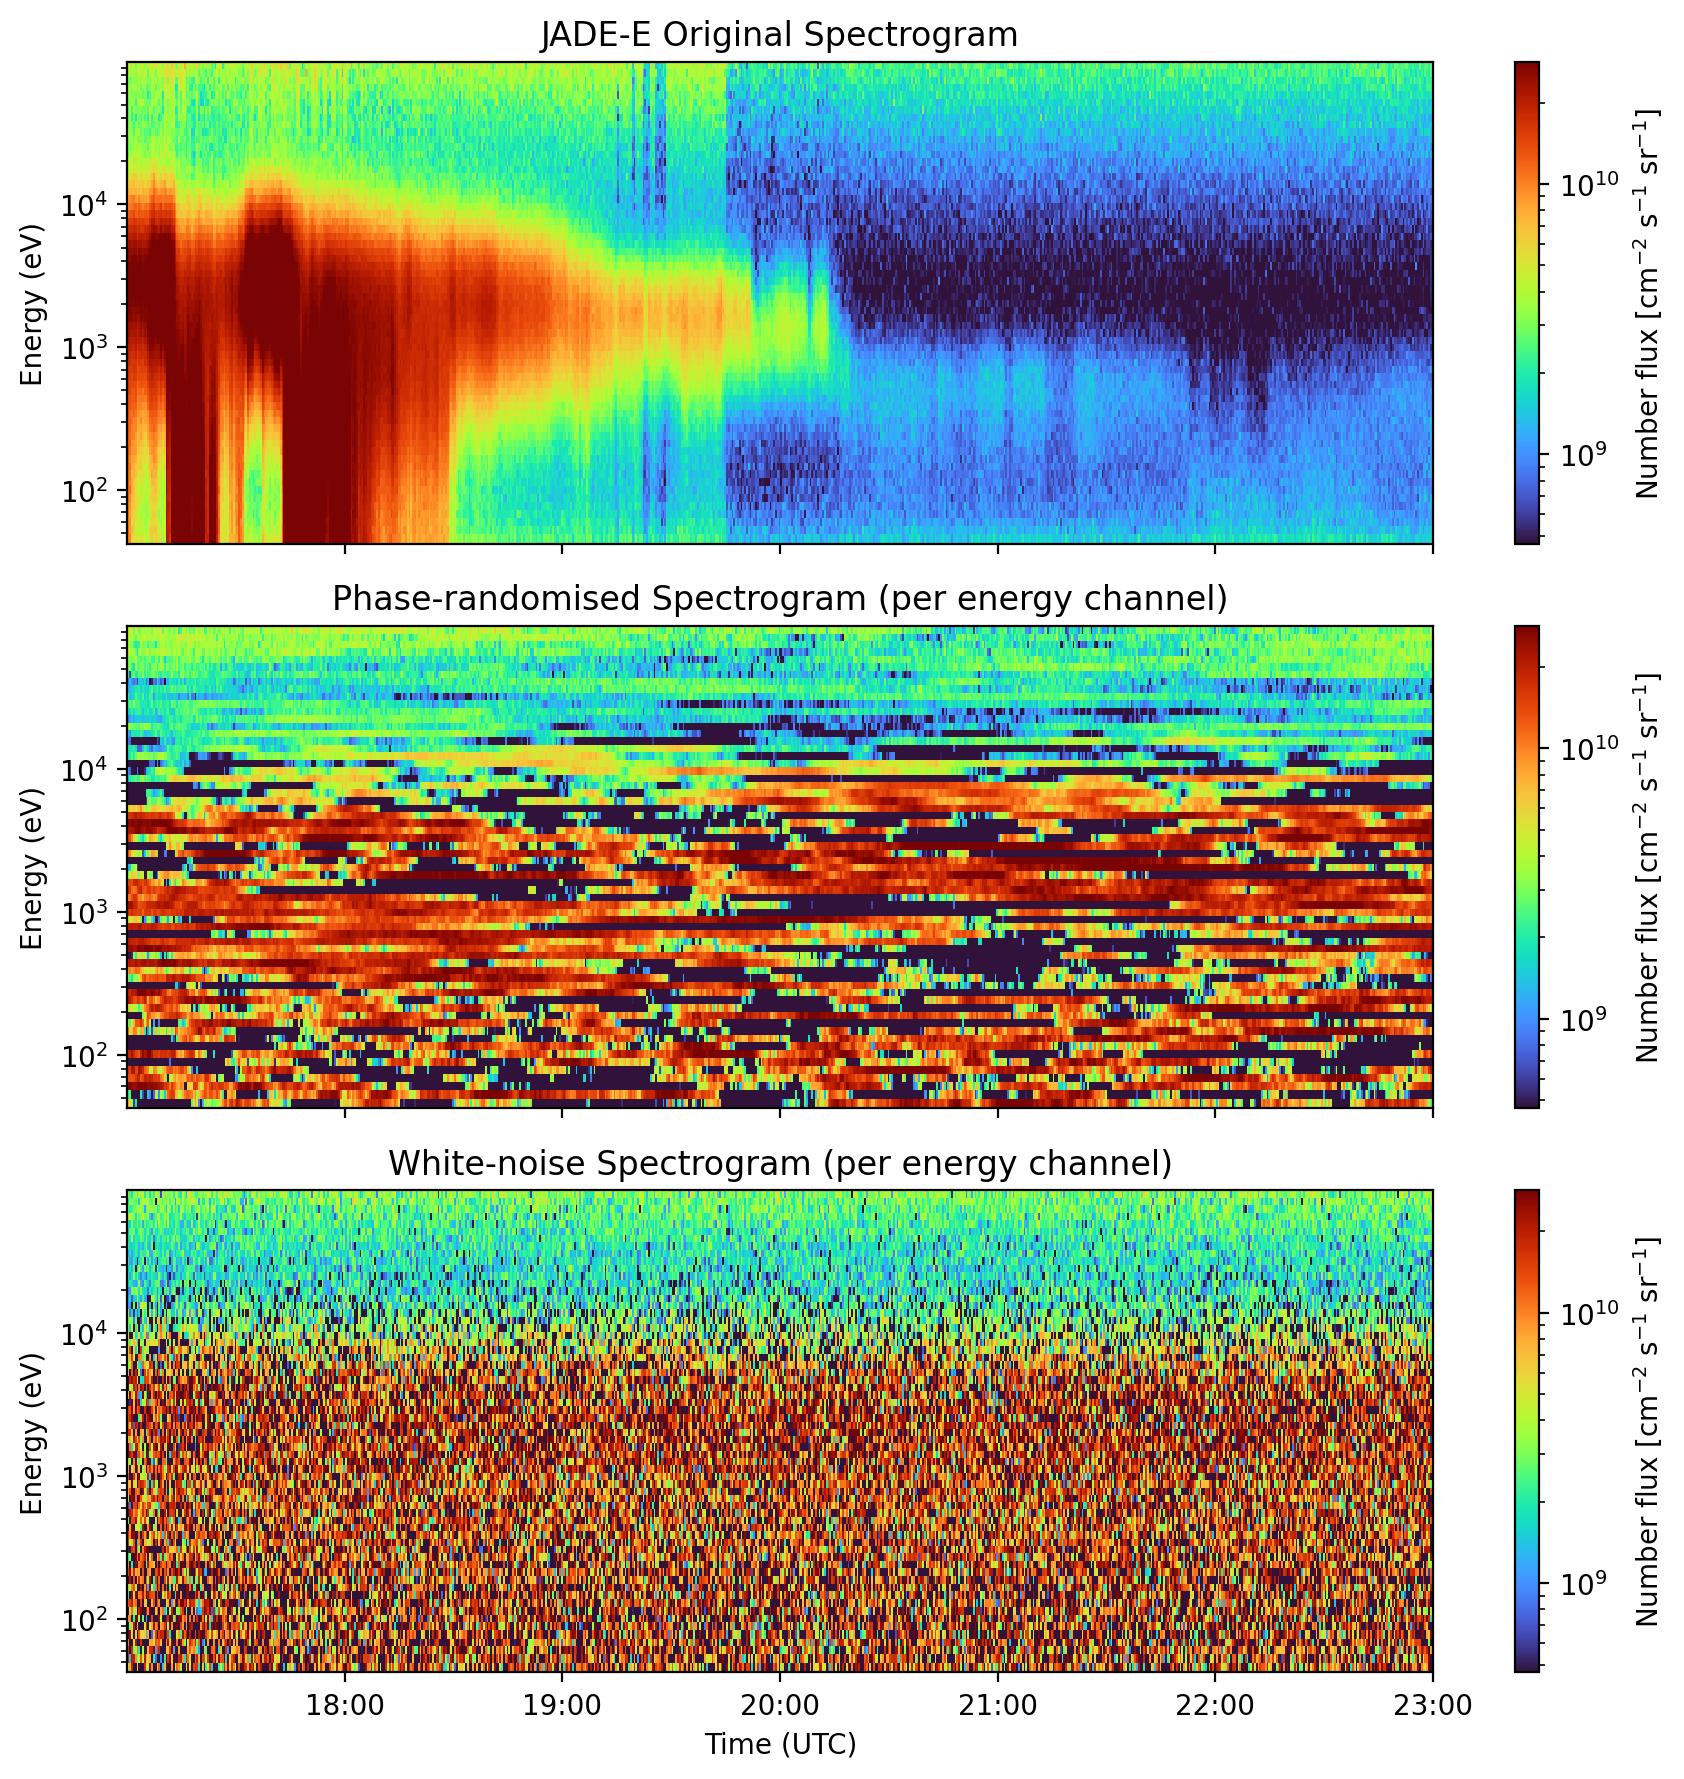

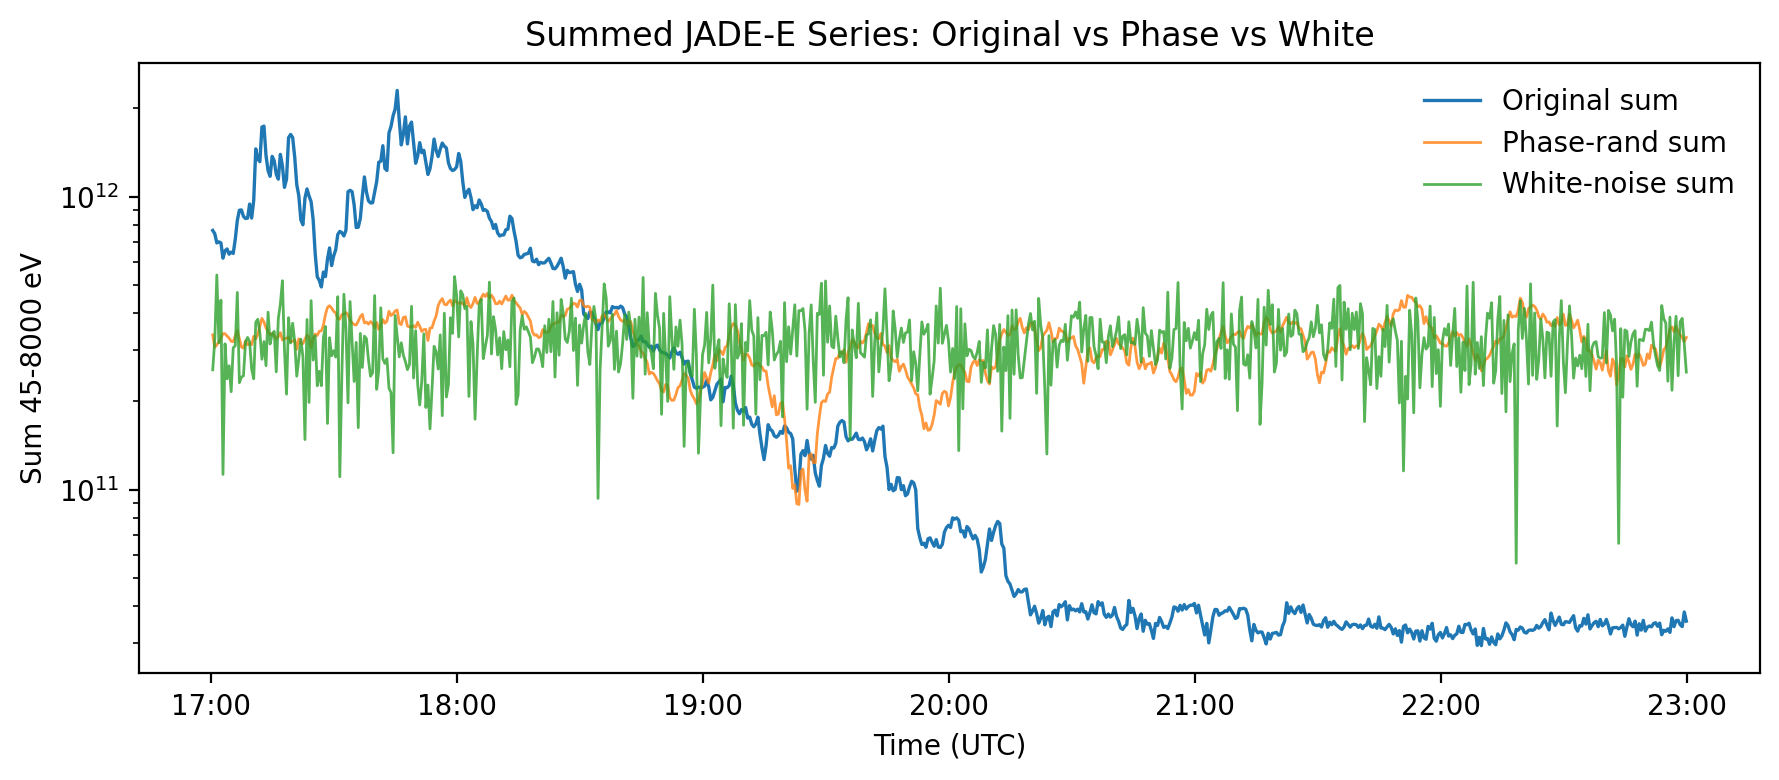

In [45]:
import re
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import matplotlib.dates as mdates
from matplotlib.colors import LogNorm
import pdr

# -------------------------------------------------------------------
# USER SETTINGS
# -------------------------------------------------------------------
LBL_PATH      = "Data_Files/20190402 All Data/JAD_L50_LRS_ELC_ANY_DEF_2019092_V01.LBL"
START_TIME    = "2019-04-02T17:00:00"
END_TIME      = "2019-04-02T23:00:00"

ENERGY_MIN_EV = 45.0
ENERGY_MAX_EV = 8000.0

# JADE-E energy centers (same as your main script)
ENERGY_BINS_EV = np.array([
    4.5731E+001, 5.3296E+001, 6.0349E+001, 6.8611E+001, 7.7419E+001,
    8.9858E+001, 1.0039E+002, 1.1494E+002, 1.2908E+002, 1.4807E+002,
    1.6538E+002, 1.8943E+002, 2.1210E+002, 2.4241E+002, 2.7057E+002,
    3.0856E+002, 3.4290E+002, 3.9006E+002, 4.3681E+002, 4.9299E+002,
    5.5223E+002, 6.2153E+002, 6.9798E+002, 7.8441E+002, 8.8190E+002,
    9.9458E+002, 1.1175E+003, 1.2632E+003, 1.4210E+003, 1.6066E+003,
    1.8068E+003, 2.0410E+003, 2.2617E+003, 2.5464E+003, 2.9011E+003,
    3.2921E+003, 3.7061E+003, 4.1751E+003, 4.7001E+003, 5.2996E+003,
    5.9765E+003, 6.7664E+003, 7.6124E+003, 8.5852E+003, 9.6487E+003,
    1.0927E+004, 1.2282E+004, 1.3872E+004, 1.5623E+004, 1.7610E+004,
    1.9783E+004, 2.2346E+004, 2.5209E+004, 2.8414E+004, 3.2039E+004,
    3.6123E+004, 4.0668E+004, 4.5886E+004, 5.1684E+004, 5.8298E+004,
    6.5677E+004, 7.4021E+004, 8.3346E+004, 9.3975E+004
], dtype=float)

N_E, N_LOOK = 64, 48
N_COLS = N_E * N_LOOK


# -------------------------------------------------------------------
# HELPERS
# -------------------------------------------------------------------
def energy_edges_from_centers(e):
    e = np.asarray(e, float)
    mids = np.sqrt(e[:-1] * e[1:])
    return np.concatenate([[e[0]**2 / mids[0]], mids, [e[-1]**2 / mids[-1]]])


def load_jade_cube(lbl_path):
    """Return (t_edges, t_centers, e_sorted, e_edges, Zp)."""
    ds = pdr.read(lbl_path)
    df = ds["TABLE"]

    t_lo = pd.to_datetime(df["DIM0_UTC_LOWER"].astype(str),
                          format="%Y-%jT%H:%M:%S.%f", utc=False)
    t_hi = pd.to_datetime(df["DIM0_UTC_UPPER"].astype(str),
                          format="%Y-%jT%H:%M:%S.%f", utc=False)

    pat = re.compile(r"^DATA_(\d+)$", re.IGNORECASE)
    pairs = []
    for c in df.columns:
        m = pat.match(str(c))
        if m:
            pairs.append((int(m.group(1)), c))
    pairs.sort(key=lambda x: x[0])
    data_cols = [c for _, c in pairs]
    if len(data_cols) != N_COLS:
        raise ValueError(f"Expected {N_COLS} DATA cols, got {len(data_cols)}")

    raw = df[data_cols].to_numpy(dtype=float)
    raw[raw <= -9.0e5] = np.nan

    nt = len(df)
    cube   = raw.reshape(nt, N_E, N_LOOK)
    Z_mean = np.nanmean(cube, axis=2)  # (T, 64)

    mask = t_lo.notna() & t_hi.notna()
    t_lo = t_lo[mask].reset_index(drop=True)
    t_hi = t_hi[mask].reset_index(drop=True)
    Z_mean = Z_mean[mask.values, :]

    ord_idx = np.argsort(t_lo.values)
    t_lo = t_lo.iloc[ord_idx].reset_index(drop=True)
    t_hi = t_hi.iloc[ord_idx].reset_index(drop=True)
    Z_mean = Z_mean[ord_idx, :]

    t_edges   = pd.DatetimeIndex(np.concatenate([t_lo.values[:1], t_hi.values]))
    t_centers = t_lo + (t_hi - t_lo) / 2

    sorter   = np.argsort(ENERGY_BINS_EV)
    e_sorted = ENERGY_BINS_EV[sorter]
    Zp       = Z_mean[:, sorter]
    e_edges  = energy_edges_from_centers(e_sorted)

    return t_edges, t_centers, e_sorted, e_edges, Zp


def generate_surrogate_phase(x):
    """Phase-randomised surrogate with same amplitude spectrum."""
    x = np.asarray(x, float)
    n = len(x)
    Xf = np.fft.rfft(x)
    phase = np.exp(1j * 2.0 * np.pi * np.random.rand(len(Xf)))
    phase[0] = 1.0
    if n % 2 == 0:
        phase[-1] = 1.0
    Xf_rand = np.abs(Xf) * phase
    return np.fft.irfft(Xf_rand, n=n)


def generate_surrogate_white(x):
    """Gaussian white-noise surrogate with same mean, std as x."""
    x = np.asarray(x, float)
    m = np.nanmean(x)
    s = np.nanstd(x, ddof=1)
    return m + s * np.random.normal(size=x.size)


# -------------------------------------------------------------------
# MAIN DEMO
# -------------------------------------------------------------------
def demo_jade_phase_and_white_surrogates():
    # --- Load JADE cube ---
    t_edges, t_centers, e_sorted, e_edges, Zp = load_jade_cube(LBL_PATH)

    # --- Window in time ---
    t0 = pd.to_datetime(START_TIME)
    t1 = pd.to_datetime(END_TIME)
    mask_t = (t_centers >= t0) & (t_centers <= t1)

    times_win = t_centers[mask_t].to_numpy(dtype="datetime64[ns]")
    Z_win     = Zp[mask_t.values, :]               # (Nt, 64)

    # --- Time edges for pcolormesh ---
    idx0 = np.where(t_centers.to_numpy() >= times_win[0])[0][0]
    idx1 = np.where(t_centers.to_numpy() <= times_win[-1])[0][-1]
    t_edges_win = t_edges[idx0: idx1 + 2]          # edges have length Nt+1

    # --- Build phase-randomised and white-noise surrogates per channel ---
    Z_phase = np.full_like(Z_win, np.nan)
    Z_white = np.full_like(Z_win, np.nan)

    for j in range(Z_win.shape[1]):
        col = Z_win[:, j]
        m = np.isfinite(col)
        if not np.any(m):
            continue

        col_f = col[m]

        # Phase-randomised around channel mean (preserve envelope-ish)
        baseline = np.nanmean(col_f)
        fluct    = col_f - baseline
        phase_fluct = generate_surrogate_phase(fluct)
        Z_phase[m, j] = baseline + phase_fluct

        # White-noise surrogate: same mean/std, uncorrelated in time
        Z_white[m, j] = generate_surrogate_white(col_f)

    # --- Common color scaling based on original ---
    Zpos = Z_win[np.isfinite(Z_win) & (Z_win > 0)]
    if Zpos.size == 0:
        raise RuntimeError("No positive values in original Z_win.")
    vmin, vmax = np.nanpercentile(Zpos, [5, 95])
    vmin = max(vmin, np.nextafter(0.0, 1.0))
    eps  = vmin * 1e-3  # small positive floor for log plots

    def make_log_safe(Z):
        Zp = np.where(np.isfinite(Z), Z, np.nan)
        Zp = np.where(Zp > eps, Zp, eps)
        return Zp

    Z_phase_plot = make_log_safe(Z_phase)
    Z_white_plot = make_log_safe(Z_white)

    # -------------------------------------------------------------------
    # 1) Spectrograms: original vs phase vs white
    # -------------------------------------------------------------------
    fig1, axes = plt.subplots(3, 1, figsize=(9, 9), dpi=200, sharex=True)

    ax1, ax2, ax3 = axes

    pcm1 = ax1.pcolormesh(
        t_edges_win, e_edges, Z_win.T,
        shading="auto", norm=LogNorm(vmin=vmin, vmax=vmax), cmap="turbo"
    )
    ax1.set_yscale("log")
    ax1.set_ylabel("Energy (eV)")
    ax1.set_title("JADE-E Original Spectrogram")
    ax1.set_facecolor("black")
    fig1.colorbar(pcm1, ax=ax1, label="Number flux [cm$^{-2}$ s$^{-1}$ sr$^{-1}$]")

    pcm2 = ax2.pcolormesh(
        t_edges_win, e_edges, Z_phase_plot.T,
        shading="auto", norm=LogNorm(vmin=vmin, vmax=vmax), cmap="turbo"
    )
    ax2.set_yscale("log")
    ax2.set_ylabel("Energy (eV)")
    ax2.set_title("Phase-randomised Spectrogram (per energy channel)")
    ax2.set_facecolor("black")
    fig1.colorbar(pcm2, ax=ax2, label="Number flux [cm$^{-2}$ s$^{-1}$ sr$^{-1}$]")

    pcm3 = ax3.pcolormesh(
        t_edges_win, e_edges, Z_white_plot.T,
        shading="auto", norm=LogNorm(vmin=vmin, vmax=vmax), cmap="turbo"
    )
    ax3.set_yscale("log")
    ax3.set_ylabel("Energy (eV)")
    ax3.set_title("White-noise Spectrogram (per energy channel)")
    ax3.set_facecolor("black")
    cb3 = fig1.colorbar(pcm3, ax=ax3, label="Number flux [cm$^{-2}$ s$^{-1}$ sr$^{-1}$]")

    ax3.set_xlabel("Time (UTC)")
    ax3.xaxis.set_major_formatter(mdates.DateFormatter("%H:%M"))

    fig1.tight_layout()

    # -------------------------------------------------------------------
    # 2) Summed-between-lines time series: original vs phase vs white
    # -------------------------------------------------------------------
    mask_e = (e_sorted >= ENERGY_MIN_EV) & (e_sorted <= ENERGY_MAX_EV)

    summed_orig  = np.nansum(Z_win[:,   mask_e], axis=1)
    summed_phase = np.nansum(Z_phase[:, mask_e], axis=1)
    summed_white = np.nansum(Z_white[:, mask_e], axis=1)

    fig2, ax = plt.subplots(figsize=(9, 4), dpi=200)
    ax.plot(times_win, summed_orig,  label="Original sum", lw=1.2)
    ax.plot(times_win, summed_phase, label="Phase-rand sum", lw=1.0, alpha=0.8)
    ax.plot(times_win, summed_white, label="White-noise sum", lw=1.0, alpha=0.8)

    ax.set_yscale("log")
    ax.set_xlabel("Time (UTC)")
    ax.set_ylabel(f"Sum {ENERGY_MIN_EV:.0f}-{ENERGY_MAX_EV:.0f} eV")
    ax.set_title("Summed JADE-E Series: Original vs Phase vs White")
    ax.xaxis.set_major_formatter(mdates.DateFormatter("%H:%M"))
    ax.legend(frameon=False)
    fig2.tight_layout()

    plt.show()


if __name__ == "__main__":
    demo_jade_phase_and_white_surrogates()
